same but different experiments

In [1]:
#cell that have all of the imports
# Data
import numpy as np
import pandas as pd

# visualization
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

# pytorch
import torch
import torch.nn.functional as F
from torch import nn, tensor
from torch.utils.data import DataLoader, Dataset

# torchvision
from torchvision import transforms, models
from torchvision.transforms import functional as TF

# fastai
from fastai.vision.all import *
from fastai.tabular.all import *
from fastai.data.transforms import RandomSplitter
from fastai.callback.hook import *

# sklearn
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#now we have got the Data lets unzip
import os
os.getcwd()
# get current working directory

'/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/fast_ai'

In [3]:
#make the Data paths
data_path = Path('../Data/plant_comp')
big_trn_path = data_path / "train_images"
test_path = data_path / "test_images"

 now we are going to resize the images of the training becasue if we make it as always, where it is made on the fly during the training --->this will make the weak kaggle cpu bottleneck the gpu    --THAT IS TO MAKE THE EXPERIMENTATION MORE FAST AND EASY AND AT THE END WHEN WE FIND THE BEST SETTING WE MAKE THE FULL IMAGES--


In [4]:
# so we are going to  make a folder for the resized images
trn_path =  data_path/"small_train_images"
# now we make the resize
resize_images(trn_path,
              dest=trn_path,
              max_size=256,  # make the maximum size =256
              recurse=True) # make this in all of the subfolders

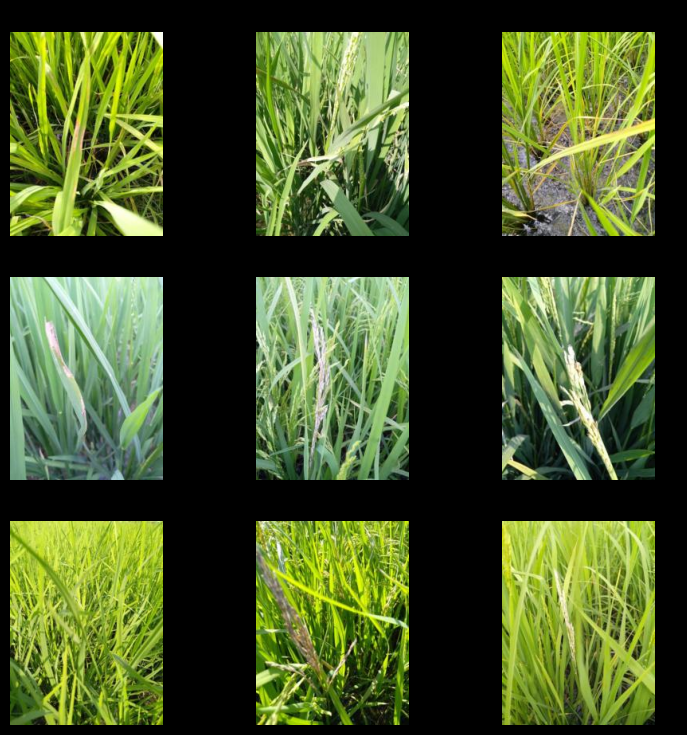

In [5]:
#now make the dls
dls = ImageDataLoaders.from_folder(trn_path,
                                   valid_pct=0.2,
                                   shuffle=True,
                                   item_tfms=Resize((256,192))) # we didnt need the image to be exactly this in the resize_images becasue the main goal from it is to make the pic load faster and this small change that we make now wont take much time because the image is already small

dls.show_batch() # the batch_size is 64 by default in -->ImageDataLoaders.from_folder

In [6]:
#we are going to make a training funciton so that we can have easier experimentations
def train(arch:"model_name" ,item_tfms,batch_tfms,lr=0.01,batch_size=64,epochs=5):
    dls = ImageDataLoaders.from_folder(trn_path,
                                       valid_pct=0.2,
                                       bs=batch_size,
                                       item_tfms=item_tfms,
                                       batch_tfms=batch_tfms)# that is a tfm that is made for the batch in the gpu and it is mostly for making the augmentations
    learn = vision_learner(dls,
                           arch,
                           metrics=[accuracy,error_rate]).to_fp16()
    learn.fine_tune(epochs,lr)
    return learn

In [7]:
# lets try our function
learn = train(arch='resnet26d',
              item_tfms=Resize(192),
              batch_tfms=aug_transforms(size=128, min_scale=0.75))

epoch,train_loss,valid_loss,accuracy,error_rate,time
0,1.923539,1.525163,0.532436,0.467564,00:12


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,1.283663,0.984043,0.680442,0.319558,00:12
1,1.009031,0.704823,0.772225,0.227775,00:12
2,0.719867,0.482848,0.846228,0.153772,00:12
3,0.519893,0.388692,0.881788,0.118212,00:12
4,0.434953,0.359625,0.888996,0.111004,00:12


see the training time is much faster because of the crop that we made earlier (30s--->12s)

In [8]:
learn = train(arch='convnext_small_in22k',
              item_tfms=Resize(192),
              batch_tfms=aug_transforms(size=128, min_scale=0.75))

/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/.venv/lib/python3.12/site-packages/timm/models/_factory.py:138: UserWarning: Mapping deprecated model name convnext_small_in22k to current convnext_small.fb_in22k.
  model = create_fn(


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,1.327522,0.756747,0.745795,0.254205,00:18


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.685165,0.484636,0.838059,0.161941,00:23
1,0.557880,0.336800,0.893321,0.106679,00:24
2,0.351370,0.245114,0.925517,0.074483,00:25
3,0.225470,0.164449,0.949063,0.050937,00:24
4,0.168269,0.157185,0.959635,0.040365,00:24


In [9]:
# let's see if we made the resizing into making it a square with squishing method instead of the crop , would it make a difference
learn = train(arch='convnext_small_in22k',
              item_tfms=Resize(192,method='squish'),
              batch_tfms=aug_transforms(size=128, min_scale=0.75))

epoch,train_loss,valid_loss,accuracy,error_rate,time
0,1.301308,0.853416,0.734262,0.265738,00:17


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.638418,0.519289,0.839020,0.160980,00:24
1,0.481772,0.336993,0.901009,0.098991,00:23
2,0.310164,0.215326,0.936088,0.063912,00:24
3,0.196445,0.153105,0.953388,0.046612,00:24
4,0.123859,0.135560,0.957232,0.042768,00:23


In [10]:
# now lets see if we made it by the padding --> with zeros (black pixels)
learn = train(arch='convnext_small_in22k',
              item_tfms=Resize((256,192),method=ResizeMethod.Pad,pad_mode=PadMode.Zeros),
              batch_tfms=aug_transforms(size=128, min_scale=0.75))

epoch,train_loss,valid_loss,accuracy,error_rate,time
0,1.238304,0.926066,0.710716,0.289284,00:17


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.649424,0.424770,0.867852,0.132148,00:25
1,0.534529,0.391870,0.873138,0.126862,00:24
2,0.322162,0.213498,0.932725,0.067275,00:23
3,0.197800,0.152015,0.954829,0.045171,00:23
4,0.139228,0.138170,0.954829,0.045171,00:23


In [11]:
# now we are going to try a method called test time augmentation (TTA) ---> make at inference 5 augmentations of the same photo --> makes better prediction and more accurate

# now lets check the stats of the last model
validation_dls=learn.dls.valid
pred_probs , real_labels  = learn.get_preds(dl=validation_dls)

In [12]:
# this functions make the argmax for us
error_rate(pred_probs,real_labels).item(), accuracy(pred_probs,real_labels).item()

(0.045170605182647705, 0.9548293948173523)

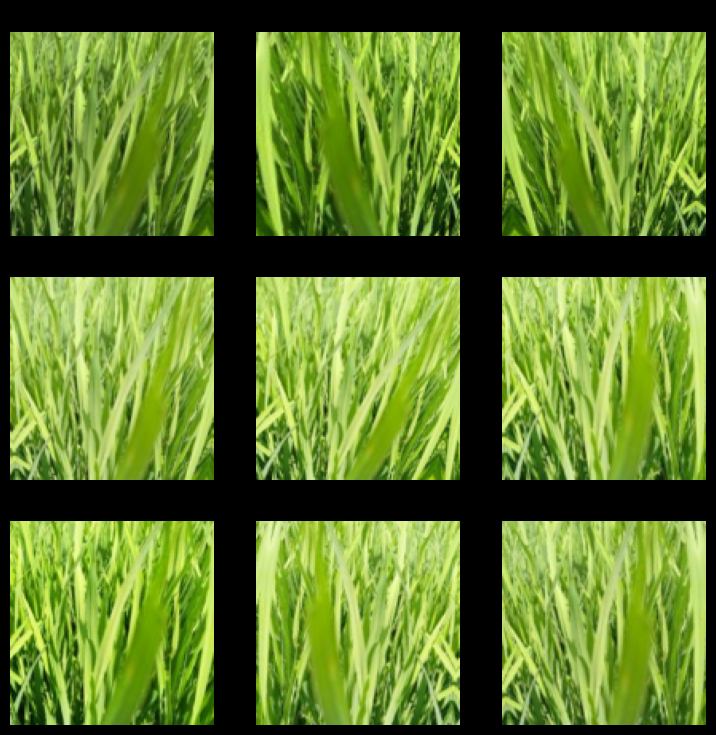

In [13]:
# now let's see what the model does when training_dls (augmentation)
learn.dls.train.show_batch(max_n=9,unique=True) # this unique param makes us see the same pic with different augmentations

In [14]:
# lets now try the tta and look what is going to happen
tta_pred_probs,real_labels = learn.tta(dl=validation_dls)

epoch,train_loss,valid_loss,accuracy,error_rate,time


<div></div>

In [15]:
#lets see
error_rate(tta_pred_probs,real_labels).item(), accuracy(tta_pred_probs,real_labels).item()

(0.03652089834213257, 0.9634791016578674)

## SCALE IT UP

In [16]:
trn_path = big_trn_path

In [17]:
# clear the memory of the cuda becassue we have had a OutOfMemoryError
import gc
import torch

# delete old learner if it exists
del learn
gc.collect()                # clear Python memory
torch.cuda.empty_cache()    # clear GPU memory

In [18]:
# verify it worked:
print(torch.cuda.memory_allocated() / 1024**3, "GB allocated")
print(torch.cuda.memory_reserved() / 1024**3,  "GB reserved")

0.015874385833740234 GB allocated
0.05078125 GB reserved


In [19]:
# lets make the scaled training
learn = train("convnext_small_in22k",
              epochs=12,
              item_tfms=Resize((480, 360),
                               method=ResizeMethod.Pad, pad_mode=PadMode.Zeros),
              batch_tfms=aug_transforms(size=(256,192),
                                        min_scale=0.75),
              batch_size=32) # to avoid the OutOfMemoryError

epoch,train_loss,valid_loss,accuracy,error_rate,time
0,1.116642,0.731713,0.779913,0.220087,00:50


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.547536,0.337013,0.894282,0.105718,01:05
1,0.422126,0.239328,0.924075,0.075925,01:05
2,0.373066,0.266353,0.919270,0.080730,01:04
3,0.315621,0.186149,0.939933,0.060067,01:04
4,0.250244,0.181556,0.944738,0.055262,01:04
5,0.189356,0.164132,0.955310,0.044690,01:04
6,0.147364,0.123540,0.962038,0.037963,01:05
7,0.104214,0.107617,0.968765,0.031235,01:05
8,0.073780,0.098974,0.972129,0.027871,01:05
9,0.051640,0.086786,0.977895,0.022105,01:05


In [23]:
#now lets check it with the tta
validation_dls = learn.dls.valid
tta_pred_probs,real_labels = learn.tta(dl=validation_dls)
#lets see
error_rate(tta_pred_probs,real_labels).item(), accuracy(tta_pred_probs,real_labels).item()

epoch,train_loss,valid_loss,accuracy,error_rate,time


<div></div>

(0.01970207691192627, 0.9802979230880737)

## submissions

In [24]:
data_path

Path('plant_comp')

In [25]:
# get the test files
test_files = get_image_files(test_path).sorted()
test_files

(#3469) [Path('plant_comp/test_images/200001.jpg'), Path('plant_comp/test_images/200002.jpg'), Path('plant_comp/test_images/200003.jpg'), Path('plant_comp/test_images/200004.jpg'), Path('plant_comp/test_images/200005.jpg'), Path('plant_comp/test_images/200006.jpg'), Path('plant_comp/test_images/200007.jpg'), Path('plant_comp/test_images/200008.jpg'), Path('plant_comp/test_images/200009.jpg'), Path('plant_comp/test_images/200010.jpg'), Path('plant_comp/test_images/200011.jpg'), Path('plant_comp/test_images/200012.jpg'), Path('plant_comp/test_images/200013.jpg'), Path('plant_comp/test_images/200014.jpg'), Path('plant_comp/test_images/200015.jpg'), Path('plant_comp/test_images/200016.jpg'), Path('plant_comp/test_images/200017.jpg'), Path('plant_comp/test_images/200018.jpg'), Path('plant_comp/test_images/200019.jpg'), Path('plant_comp/test_images/200020.jpg'), Path('plant_comp/test_images/200021.jpg'), Path('plant_comp/test_images/200022.jpg'), Path('plant_comp/test_images/200023.jpg'), Pa

In [26]:
# make the dl
test_dl = learn.dls.test_dl(test_files)
test_dl

In [27]:
# make the predicitons
test_preds_probs , _ = learn.tta(dl=test_dl) # the _ is targets, empty for test set, thrown away

epoch,train_loss,valid_loss,accuracy,error_rate,time


<div></div>

In [28]:
# getting the argmax indxs for the rows
idxs = test_preds_probs.argmax(dim=1)

In [30]:
#getting the list of the names of the classes
classes = np.array(learn.dls.vocab)
classes

array(['bacterial_leaf_blight', 'bacterial_leaf_streak',
       'bacterial_panicle_blight', 'blast', 'brown_spot', 'dead_heart',
       'downy_mildew', 'hispa', 'normal', 'tungro'], dtype='<U24')

In [31]:
# making a series
# SERIES ﷿﷿﷿ one column, one index:
# DATAFRAME ﷿﷿﷿ multiple columns, one index:
results = pd.Series(classes[idxs],name="idxs")
results

0                       hispa
1                      normal
2                       blast
3                       blast
4                       blast
                ...          
3464               dead_heart
3465                    hispa
3466                   normal
3467    bacterial_leaf_streak
3468               dead_heart
Name: idxs, Length: 3469, dtype: str

In [32]:
# make the df
ss = pd.read_csv(data_path/"sample_submission.csv")
ss

,image_id,label
0,200001.jpg,NaN
1,200002.jpg,NaN
2,200003.jpg,NaN
3,200004.jpg,NaN
4,200005.jpg,NaN
...,...,...
3464,203465.jpg,NaN
3465,203466.jpg,NaN
3466,203467.jpg,NaN
3467,203468.jpg,NaN


In [33]:
ss["label"] = results
ss

,image_id,label
0,200001.jpg,hispa
1,200002.jpg,normal
2,200003.jpg,blast
3,200004.jpg,blast
4,200005.jpg,blast
...,...,...
3464,203465.jpg,dead_heart
3465,203466.jpg,hispa
3466,203467.jpg,normal
3467,203468.jpg,bacterial_leaf_streak


In [34]:
ss.to_csv(data_path/"submission_2.csv",index=False)

In [35]:
!head ./plant_comp/submission_2.csv

image_id,label
200001.jpg,hispa
200002.jpg,normal
200003.jpg,blast
200004.jpg,blast
200005.jpg,blast
200006.jpg,brown_spot
200007.jpg,dead_heart
200008.jpg,brown_spot
200009.jpg,hispa
